### Lab Assignment - 7 
#### Image Representation, PCA, Eigenfaces and Face Recognition

##### Part A - Image Representation 

X: (400, 10304) y: (400,)
pixel range: 0.0 to 251.0
train: (320, 10304) test: (80, 10304)


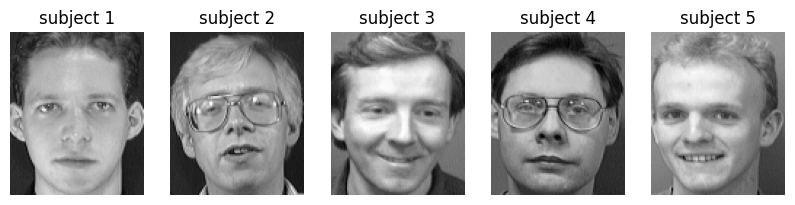

In [3]:
import numpy as np
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

DATA_DIR = Path("data")   
H, W = 112, 92

def load_orl(data_dir: Path):
    X, y = [], []
    for subj in range(1, 41):
        for img_id in range(1, 11):
            img = Image.open(data_dir / f"s{subj}" / f"{img_id}.pgm")
            arr = np.asarray(img, dtype=np.float64)       # (112, 92) pixel matrix
            X.append(arr.flatten())                        # (10304,) feature vector
            y.append(subj)
    return np.array(X), np.array(y)

X, y = load_orl(DATA_DIR)
print("X:", X.shape, "y:", y.shape)                        # expect (400, 10304) (400,)
print("pixel range:", X.min(), "to", X.max())

def stratified_split(y, n_train=8, seed=42):
    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for s in np.unique(y):
        idx = rng.permutation(np.where(y == s)[0])
        train_idx += idx[:n_train].tolist()
        test_idx += idx[n_train:].tolist()
    return np.array(train_idx), np.array(test_idx)

tr, te = stratified_split(y)
X_train, y_train = X[tr], y[tr]
X_test, y_test = X[te], y[te]
print("train:", X_train.shape, "test:", X_test.shape)     # (320, 10304) (80, 10304)

# sanity: every subject appears in both sets
assert set(y_train) == set(y_test) == set(range(1, 41))

fig, ax = plt.subplots(1, 5, figsize=(10, 3))
for a, i in zip(ax, [0, 10, 20, 30, 40]):
    a.imshow(X[i].reshape(H, W), cmap="gray"); a.axis("off"); a.set_title(f"subject {y[i]}")
plt.show()

##### Part B - PCA, Eigenfaces and Compression

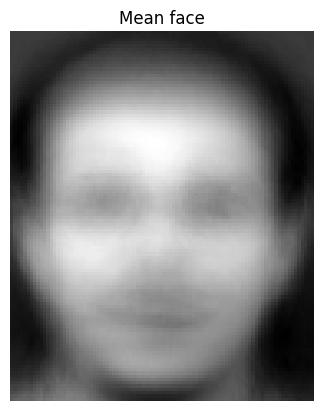

components kept (eig): 319
eigenvalues match: True
min |cos| over top 100 components: 0.9999999999999964
top 5 eigenvalues (eig): [2837009.98929293 2013339.00426591 1131088.32713936  899267.53112397
  794485.75315848]
top 5 eigenvalues (svd): [2837009.98929294 2013339.00426591 1131088.32713936  899267.53112397
  794485.75315848]


In [4]:
# --- Mean face and centering ---
mean_face = X_train.mean(axis=0)            # (10304,)
Xc = X_train - mean_face                    # (320, 10304)
n = Xc.shape[0]

plt.imshow(mean_face.reshape(H, W), cmap="gray")
plt.title("Mean face"); plt.axis("off"); plt.show()

# --- Method 1: eigendecomposition (via the small n x n matrix) ---
G = (Xc @ Xc.T) / (n - 1)                   # (320, 320)
eigvals, eigvecs = np.linalg.eigh(G)        # ascending order
order = np.argsort(eigvals)[::-1]           # sort descending
eigvals, eigvecs = eigvals[order], eigvecs[:, order]

keep = eigvals > 1e-10 * eigvals[0]         # drop the ~0 eigenvalue(s)
eigvals, eigvecs = eigvals[keep], eigvecs[:, keep]
r = len(eigvals)

comp_eig = Xc.T @ eigvecs                   # (10304, r) map back to pixel space
comp_eig /= np.linalg.norm(comp_eig, axis=0)
comp_eig = comp_eig.T                       # (r, 10304), one eigenface per row

# --- Method 2: SVD ---
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
eigvals_svd = S**2 / (n - 1)
comp_svd = Vt                               # (320, 10304)

# --- Compare the two ---
print("components kept (eig):", r)
print("eigenvalues match:", np.allclose(eigvals, eigvals_svd[:r]))
cos = np.abs(np.sum(comp_eig[:100] * comp_svd[:100], axis=1))
print("min |cos| over top 100 components:", cos.min())   # should be ~1.0
print("top 5 eigenvalues (eig):", eigvals[:5])
print("top 5 eigenvalues (svd):", eigvals_svd[:5])

k for >=90% variance: 99  (cum var = 0.9001)
  >= 80%: k = 42
  >= 95%: k = 164
  >= 99%: k = 267
compression of feature count: 10304 -> 99  (104x fewer numbers per face)


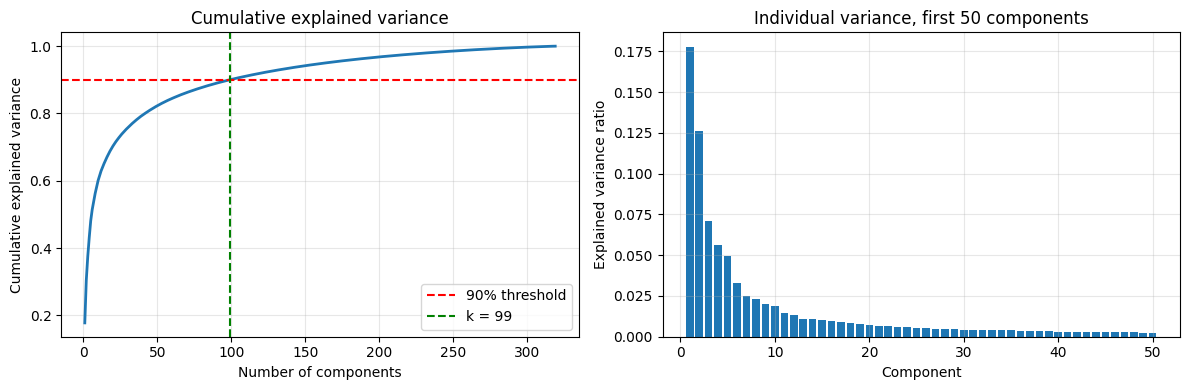

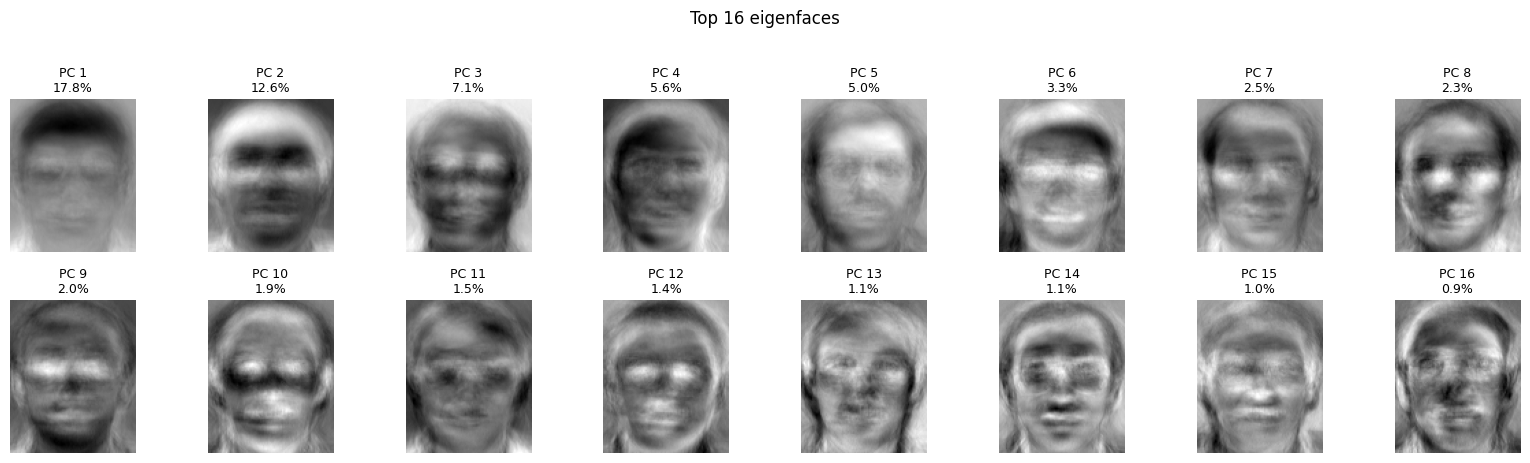

In [5]:
# --- Explained variance ---
total_var = eigvals.sum()
var_ratio = eigvals / total_var
cum_var = np.cumsum(var_ratio)

# smallest k with cumulative variance >= 90%
k90 = int(np.searchsorted(cum_var, 0.90) + 1)
print(f"k for >=90% variance: {k90}  (cum var = {cum_var[k90-1]:.4f})")
for target in (0.80, 0.95, 0.99):
    print(f"  >= {target:.0%}: k = {int(np.searchsorted(cum_var, target) + 1)}")
print(f"compression of feature count: {X_train.shape[1]} -> {k90}  "
      f"({X_train.shape[1] / k90:.0f}x fewer numbers per face)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, len(cum_var) + 1), cum_var, lw=2)
ax[0].axhline(0.90, color="r", ls="--", label="90% threshold")
ax[0].axvline(k90, color="g", ls="--", label=f"k = {k90}")
ax[0].set_xlabel("Number of components"); ax[0].set_ylabel("Cumulative explained variance")
ax[0].set_title("Cumulative explained variance"); ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].bar(range(1, 51), var_ratio[:50])
ax[1].set_xlabel("Component"); ax[1].set_ylabel("Explained variance ratio")
ax[1].set_title("Individual variance, first 50 components"); ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig("explained_variance.png", dpi=150)
plt.show()

# --- Eigenfaces: first 16 ---
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for i, a in enumerate(axes.ravel()):
    a.imshow(comp_svd[i].reshape(H, W), cmap="gray")
    a.set_title(f"PC {i+1}\n{var_ratio[i]:.1%}", fontsize=9)
    a.axis("off")
plt.suptitle("Top 16 eigenfaces", y=1.02)
plt.tight_layout()
plt.savefig("eigenfaces.png", dpi=150, bbox_inches="tight")
plt.show()

Z_train: (320, 99) Z_test: (80, 99)
train  MSE   154.13   PSNR 26.25 dB
test   MSE   323.21   PSNR 23.04 dB
train error per image: empirical 1588148.4 vs theory 1588148.4


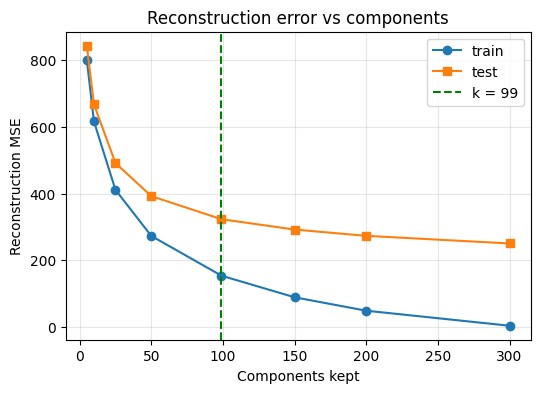

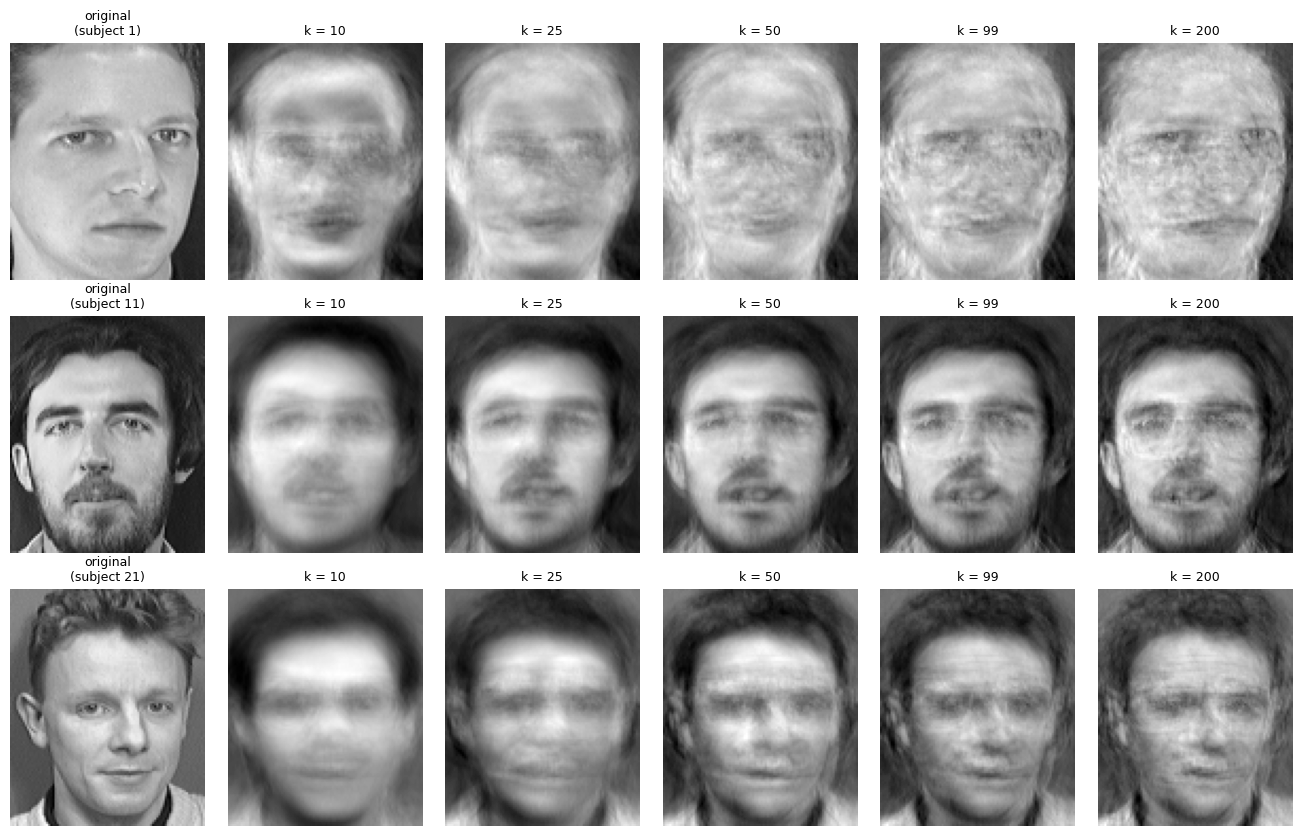

per face:  original 10304 bytes (uint8) | PCA code 792 bytes
train set: original 3.30 MB (uint8), 26.38 MB (float64)
           PCA codes 253.4 KB, plus model 8.24 MB
           codes + model 8.50 MB


In [7]:
H, W = 112, 92                                     # restore the image size (W was overwritten)

k = k90
P = comp_svd[:k]                                   # (k, 10304) principal directions

Z_train = Xc @ P.T                                 # (320, k)
Z_test = (X_test - mean_face) @ P.T                # (80, k), uses the TRAINING mean
print("Z_train:", Z_train.shape, "Z_test:", Z_test.shape)

np.savez_compressed("pca_model.npz", mean=mean_face, W=P, Z_train=Z_train, y_train=y_train)

# --- Reconstruction ---
def reconstruct(Z, W, mean):
    return Z @ W + mean

def mse(a, b):
    return np.mean((a - b) ** 2)

def psnr(a, b):
    return 10 * np.log10(255.0**2 / mse(a, b))

R_train = reconstruct(Z_train, P, mean_face)
R_test = reconstruct(Z_test, P, mean_face)
print(f"train  MSE {mse(X_train, R_train):8.2f}   PSNR {psnr(X_train, R_train):.2f} dB")
print(f"test   MSE {mse(X_test, R_test):8.2f}   PSNR {psnr(X_test, R_test):.2f} dB")

# sanity check against theory: summed squared error per image = discarded eigenvalues * (n-1)/n
emp = np.mean(np.sum((X_train - R_train) ** 2, axis=1))
theory = eigvals[k:].sum() * (n - 1) / n
print(f"train error per image: empirical {emp:.1f} vs theory {theory:.1f}")

# --- Reconstruction vs number of components ---
ks = [5, 10, 25, 50, 99, 150, 200, 300]
errs_tr, errs_te = [], []
for kk in ks:
    Wk = comp_svd[:kk]
    errs_tr.append(mse(X_train, (Xc @ Wk.T) @ Wk + mean_face))
    errs_te.append(mse(X_test, ((X_test - mean_face) @ Wk.T) @ Wk + mean_face))

plt.figure(figsize=(6, 4))
plt.plot(ks, errs_tr, "o-", label="train")
plt.plot(ks, errs_te, "s-", label="test")
plt.axvline(k90, color="g", ls="--", label=f"k = {k90}")
plt.xlabel("Components kept"); plt.ylabel("Reconstruction MSE")
plt.title("Reconstruction error vs components"); plt.legend(); plt.grid(alpha=0.3)
plt.savefig("reconstruction_error.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Visual comparison on a few TEST faces ---
show_ks = [10, 25, 50, k90, 200]
rows = [0, 20, 40]                                  # test-set indices
fig, axes = plt.subplots(len(rows), len(show_ks) + 1, figsize=(2.2 * (len(show_ks) + 1), 2.8 * len(rows)))
for r_i, idx in enumerate(rows):
    axes[r_i, 0].imshow(X_test[idx].reshape(H, W), cmap="gray")
    axes[r_i, 0].set_title(f"original\n(subject {y_test[idx]})", fontsize=9)
    for c_i, kk in enumerate(show_ks, start=1):
        Wk = comp_svd[:kk]
        rec = ((X_test[idx] - mean_face) @ Wk.T) @ Wk + mean_face
        axes[r_i, c_i].imshow(np.clip(rec, 0, 255).reshape(H, W), cmap="gray")
        axes[r_i, c_i].set_title(f"k = {kk}", fontsize=9)
for a in axes.ravel():
    a.axis("off")
plt.tight_layout()
plt.savefig("reconstructions.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Storage comparison ---
d = X_train.shape[1]
orig_uint8 = n * d * 1                              # as stored on disk (8-bit)
orig_f64 = n * d * 8                                # as loaded in memory
pca_codes = n * k * 8                               # reduced representation, float64
pca_model = (k * d + d) * 8                         # eigenfaces + mean face
print(f"per face:  original {d} bytes (uint8) | PCA code {k * 8} bytes")
print(f"train set: original {orig_uint8/1e6:.2f} MB (uint8), {orig_f64/1e6:.2f} MB (float64)")
print(f"           PCA codes {pca_codes/1e3:.1f} KB, plus model {pca_model/1e6:.2f} MB")
print(f"           codes + model {(pca_codes + pca_model)/1e6:.2f} MB")